# Question 5 – Normal Curves, Correlation and Scatter Plots
## Scenario: Study Behaviour and Academic Achievement (20 students)

| Task | Description | Marks |
|---|---|---|
| a | Prepare data; descriptive statistics for all numerical variables | 10 |
| b | Histograms with fitted normal density curves (marks, study hours) | 15 |
| c | Normality check with Q–Q plots | 10 |
| d | Customized scatter plots: hours vs marks, attendance vs marks | 15 |
| e | Pearson correlation matrix; direction and strength | 15 |
| f | Significance test of the study-hours correlation at 5% (p-value) | 15 |
| g | Compare relationships; outliers and assumptions | 10 |
| h | Summary; correlation vs causation | 10 |

> **How to use:** run all cells in order (works in Jupyter and Colab). **Exam tip:** edit only the data dictionary if the numbers change.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:.4f}".format)

## (a) Prepare the dataset and descriptive statistics  *(10 marks)*

In [2]:
data = {
    "Student":    [f"S{i}" for i in range(1, 21)],
    "StudyHours": [2, 3, 4, 5, 5, 6, 7, 8, 8, 9, 10, 11, 4, 6, 7, 9, 3, 10, 5, 8],
    "Attendance": [60, 65, 68, 70, 75, 78, 80, 82, 85, 88, 90, 94, 58, 72, 76, 84, 62, 92, 67, 79],
    "Marks":      [48, 52, 55, 61, 64, 67, 70, 75, 78, 82, 85, 91, 51, 63, 68, 80, 49, 88, 59, 73],
}
df = pd.DataFrame(data)
num_cols = ["StudyHours", "Attendance", "Marks"]

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print("Data types:\n", df.dtypes, sep="")
print("Attendance within 0-100%?", df["Attendance"].between(0, 100).all(),
      "| Marks within 0-100?", df["Marks"].between(0, 100).all(),
      "| Hours non-negative?", (df["StudyHours"] >= 0).all())
df

Shape: (20, 4)
Missing values: 0 | Duplicate rows: 0
Data types:
Student         str
StudyHours    int64
Attendance    int64
Marks         int64
dtype: object
Attendance within 0-100%? True | Marks within 0-100? True | Hours non-negative? True


,Student,StudyHours,Attendance,Marks
0,S1,2,60,48
1,S2,3,65,52
2,S3,4,68,55
3,S4,5,70,61
4,S5,5,75,64
5,S6,6,78,67
6,S7,7,80,70
7,S8,8,82,75
8,S9,8,85,78
9,S10,9,88,82


In [3]:
desc = df[num_cols].describe().T              # count, mean, std (ddof=1), min, quartiles, max
desc["median"] = df[num_cols].median()
desc["mode"] = [", ".join(map(str, df[c].mode().tolist())) for c in num_cols]
desc["range"] = desc["max"] - desc["min"]
desc["IQR"] = desc["75%"] - desc["25%"]
desc["variance"] = df[num_cols].var()
desc["CV_%"] = desc["std"] / desc["mean"] * 100
desc["skewness"] = df[num_cols].skew()        # 0 = symmetric
desc["kurtosis"] = df[num_cols].kurt()        # excess kurtosis: 0 = normal, < 0 = flatter
display(desc)

,count,mean,std,min,25%,50%,75%,max,median,mode,range,IQR,variance,CV_%,skewness,kurtosis
StudyHours,20.0000,6.5000,2.6057,2.0000,4.7500,6.5000,8.2500,11.0000,6.5000,"5, 8",9.0000,3.5000,6.7895,40.0871,0.0000,-1.0205
Attendance,20.0000,76.2500,10.8185,58.0000,67.7500,77.0000,84.2500,94.0000,77.0000,"58, 60, 62, 65, 67, 68, 70, 72, 75, 76, 78, 79, 80, 82, 84, 85, 88, 90, 92, 94",36.0000,16.5000,117.0395,14.1882,-0.0571,-1.0176
Marks,20.0000,67.9500,13.3435,48.0000,58.0000,67.5000,78.5000,91.0000,67.5000,"48, 49, 51, 52, 55, 59, 61, 63, 64, 67, 68, 70, 73, 75, 78, 80, 82, 85, 88, 91",43.0000,20.5000,178.0500,19.6373,0.1036,-1.0916


**Reading the table:** on average a student studies **6.5 hours** (SD 2.61), attends **76.25%** of classes (SD 10.82) and scores **67.95 marks** (SD 13.34). For all three variables the mean and median are close and the skewness is about 0 (−0.06 to 0.10), so the distributions are **symmetric**. The kurtosis of about −1 means they are **flatter than a normal curve (platykurtic)**: values are spread evenly across the range rather than piled up in the middle. Study hours vary the most in relative terms (**CV ≈ 40%**), attendance the least (**CV ≈ 14%**), and marks are in between (CV ≈ 20%).

## (b) Histograms with fitted normal density curves  *(15 marks)*

The normal curve is **fitted** with the sample mean $\bar{x}$ and sample SD $s$:

$$f(x) = \frac{1}{s\sqrt{2\pi}}\, e^{-\frac{(x-\bar{x})^2}{2s^2}}$$

To compare bars and curve on the same scale, the histogram uses `density=True`, so bar areas add up to 1, like the area under the curve.

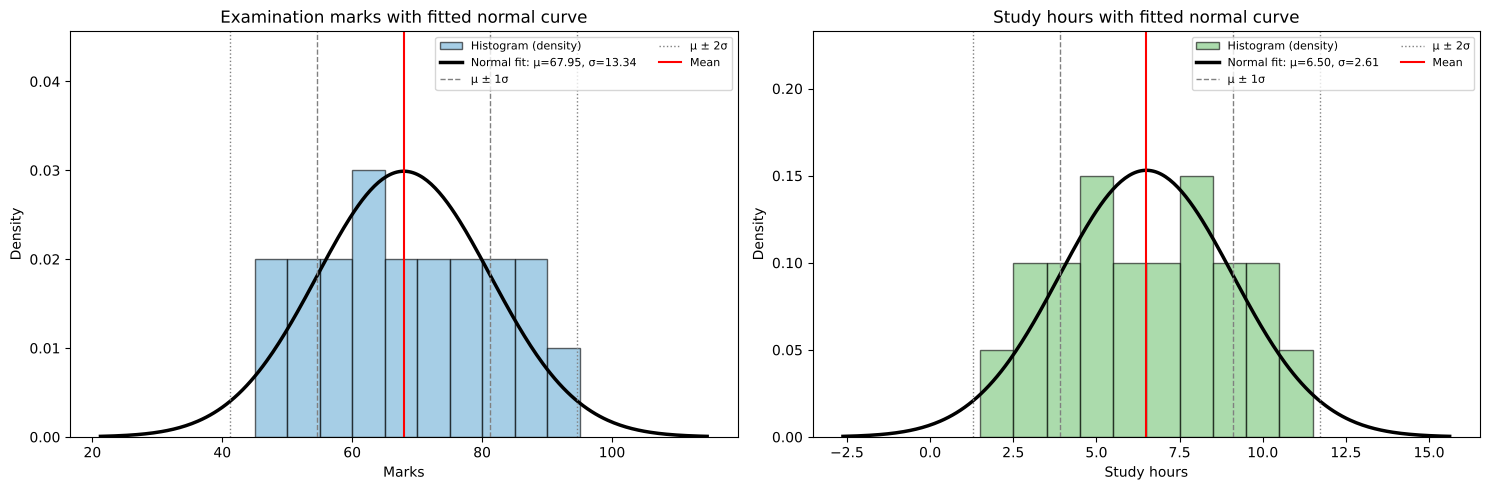

In [4]:
def hist_with_normal(ax, values, bins, color, title, xlabel):
    mu, sd = values.mean(), values.std(ddof=1)
    ax.hist(values, bins=bins, density=True, color=color, edgecolor="black", alpha=0.6, label="Histogram (density)")
    xs = np.linspace(mu - 3.5 * sd, mu + 3.5 * sd, 300)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color="black", lw=2.5, label=f"Normal fit: μ={mu:.2f}, σ={sd:.2f}")
    for k, ls in [(1, "--"), (2, ":")]:
        ax.axvline(mu - k * sd, color="grey", ls=ls, lw=1)
        ax.axvline(mu + k * sd, color="grey", ls=ls, lw=1, label=f"μ ± {k}σ")
    ax.axvline(mu, color="red", lw=1.5, label="Mean")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.45)     # headroom so the legend sits above the bars and lines
    ax.legend(fontsize=8, loc="upper right", ncol=2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
hist_with_normal(axes[0], df["Marks"], bins=np.arange(45, 100, 5), color="#6baed6",
                 title="Examination marks with fitted normal curve", xlabel="Marks")
hist_with_normal(axes[1], df["StudyHours"], bins=np.arange(1.5, 12.5, 1), color="#74c476",
                 title="Study hours with fitted normal curve", xlabel="Study hours")
plt.tight_layout()
plt.show()

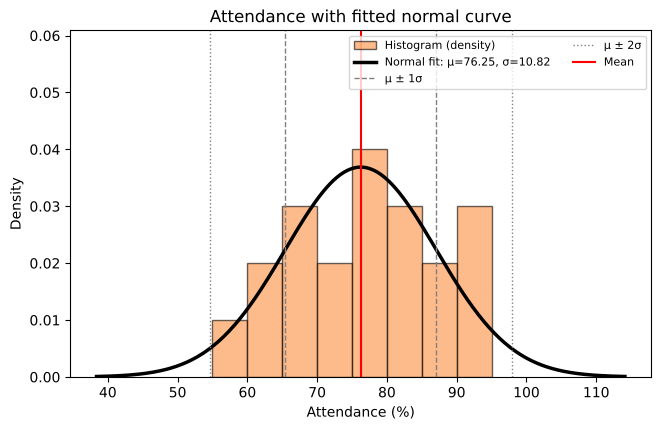

In [5]:
# Bonus: attendance too, with the same function
fig, ax = plt.subplots(figsize=(7.5, 4.5))
hist_with_normal(ax, df["Attendance"], bins=np.arange(55, 100, 5), color="#fd8d3c",
                 title="Attendance with fitted normal curve", xlabel="Attendance (%)")
plt.show()

In [6]:
# How well does the normal model describe the data? Compare observed and expected % within ±1 and ±2 SD
for col in num_cols:
    v = df[col]
    mu, sd = v.mean(), v.std(ddof=1)
    w1 = np.mean(np.abs(v - mu) <= sd) * 100
    w2 = np.mean(np.abs(v - mu) <= 2 * sd) * 100
    print(f"{col:10s}: within ±1σ = {w1:5.1f}% (normal 68.3%),  within ±2σ = {w2:5.1f}% (normal 95.4%)")

StudyHours: within ±1σ =  70.0% (normal 68.3%),  within ±2σ = 100.0% (normal 95.4%)
Attendance: within ±1σ =  60.0% (normal 68.3%),  within ±2σ = 100.0% (normal 95.4%)
Marks     : within ±1σ =  60.0% (normal 68.3%),  within ±2σ = 100.0% (normal 95.4%)


## (c) Normality check with Q–Q plots  *(10 marks)*

A **Q–Q (quantile–quantile) plot** compares the sorted data with the values expected if the data were exactly normal.
* Points **close to the straight reference line** → data is consistent with a normal distribution.
* An **S-shape** → tails lighter or heavier than normal. A **curve (banana shape)** → skewness. **Isolated points far from the line** → outliers.

The **Shapiro–Wilk test** is added as a numerical check. H₀: the data comes from a normal distribution. If p > 0.05, normality is **not rejected**.

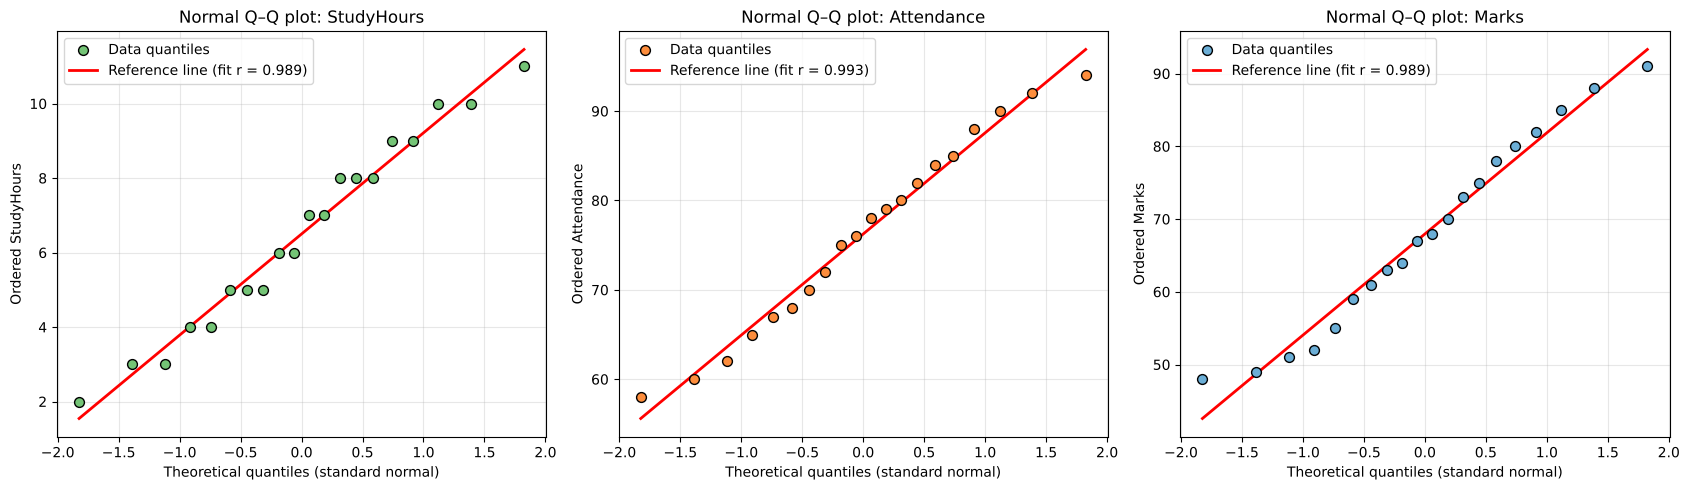

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, color in zip(axes, num_cols, ["#74c476", "#fd8d3c", "#6baed6"]):
    (osm, osr), (slope, intercept, r) = stats.probplot(df[col], dist="norm")
    ax.scatter(osm, osr, color=color, edgecolor="black", s=50, zorder=3, label="Data quantiles")
    ax.plot(osm, slope * osm + intercept, color="red", lw=2, label=f"Reference line (fit r = {r:.3f})")
    ax.set_xlabel("Theoretical quantiles (standard normal)")
    ax.set_ylabel(f"Ordered {col}")
    ax.set_title(f"Normal Q–Q plot: {col}")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
rows = []
for col in num_cols:
    W, p = stats.shapiro(df[col])
    rows.append({"Variable": col, "Shapiro-Wilk W": W, "p-value": p,
                 "Decision (α = 0.05)": "Normality NOT rejected" if p > 0.05 else "Normality rejected"})
display(pd.DataFrame(rows).set_index("Variable"))

,Shapiro-Wilk W,p-value,Decision (α = 0.05)
Variable,,,
StudyHours,0.9659,0.6662,Normality NOT rejected
Attendance,0.9700,0.7556,Normality NOT rejected
Marks,0.9604,0.5519,Normality NOT rejected


**Interpretation:** in all three Q–Q plots the points lie **close to the reference line** (Q–Q correlation 0.989–0.993), with no curvature that would indicate skewness and no isolated outliers. At both ends the points bend slightly toward the centre: the lowest value lies above the line and the highest below it. These are **light tails**, matching the negative kurtosis: the data is spread a little more evenly than a perfect bell curve, which is also visible in the flat-topped histograms in (b). The Shapiro–Wilk tests agree: **p > 0.05 for every variable, so normality is not rejected**. The normality assumption needed for the Pearson significance test in part (f) is reasonable. With only 20 observations, normality tests have limited power, so the graphical evidence is important.

## (d) Customized scatter plots  *(15 marks)*

Each scatter plot includes the **least-squares trend line**, the **Pearson r** and **R²** in the title, **point labels** (student IDs), axis labels with units, a grid and a legend. Points are **coloured by the third variable** (a colour bar), so one plot shows three variables.

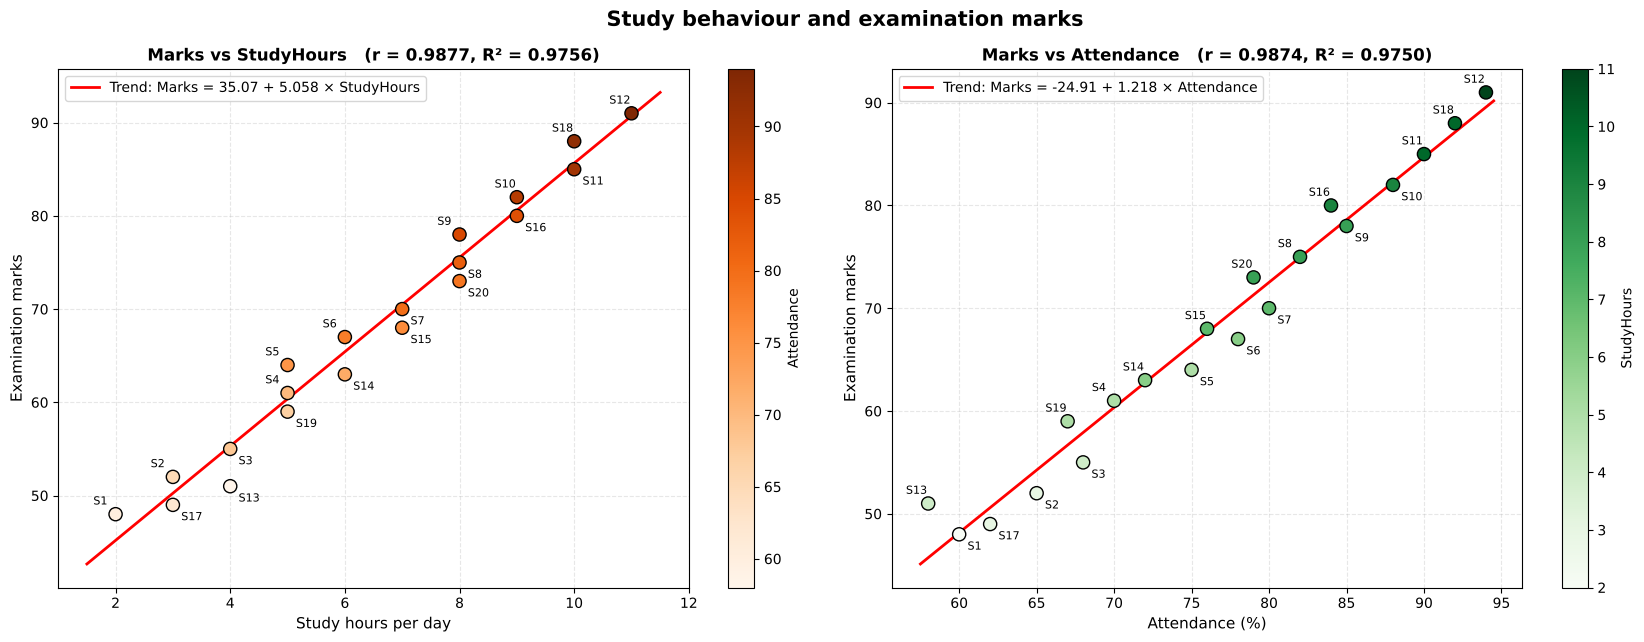

In [9]:
def scatter_with_fit(ax, xcol, ycol, ccol, xlabel, ylabel, cmap):
    x, y = df[xcol], df[ycol]
    slope, intercept = np.polyfit(x, y, 1)              # least-squares straight line
    r = x.corr(y)
    sc = ax.scatter(x, y, c=df[ccol], cmap=cmap, s=90, edgecolor="black", zorder=3)
    xs = np.linspace(x.min() - 0.5, x.max() + 0.5, 100)
    ax.plot(xs, intercept + slope * xs, color="red", lw=2,
            label=f"Trend: {ycol} = {intercept:.2f} + {slope:.3f} × {xcol}")
    # Label each point on the side away from the trend line: above-left if the point is above the line,
    # below-right if it is below. This stops labels from hiding under neighbouring points.
    for _, row in df.iterrows():
        above = row[ycol] >= intercept + slope * row[xcol]
        ax.annotate(row["Student"], (row[xcol], row[ycol]), xytext=(-16, 7) if above else (6, -11),
                    textcoords="offset points", fontsize=8)
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f"{ycol} vs {xcol}   (r = {r:.4f}, R² = {r ** 2:.4f})", fontsize=12, fontweight="bold")
    ax.grid(alpha=0.3, ls="--")
    ax.legend(loc="upper left")
    plt.colorbar(sc, ax=ax, label=ccol)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
scatter_with_fit(axes[0], "StudyHours", "Marks", "Attendance", "Study hours per day", "Examination marks", "Oranges")
scatter_with_fit(axes[1], "Attendance", "Marks", "StudyHours", "Attendance (%)", "Examination marks", "Greens")
plt.suptitle("Study behaviour and examination marks", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

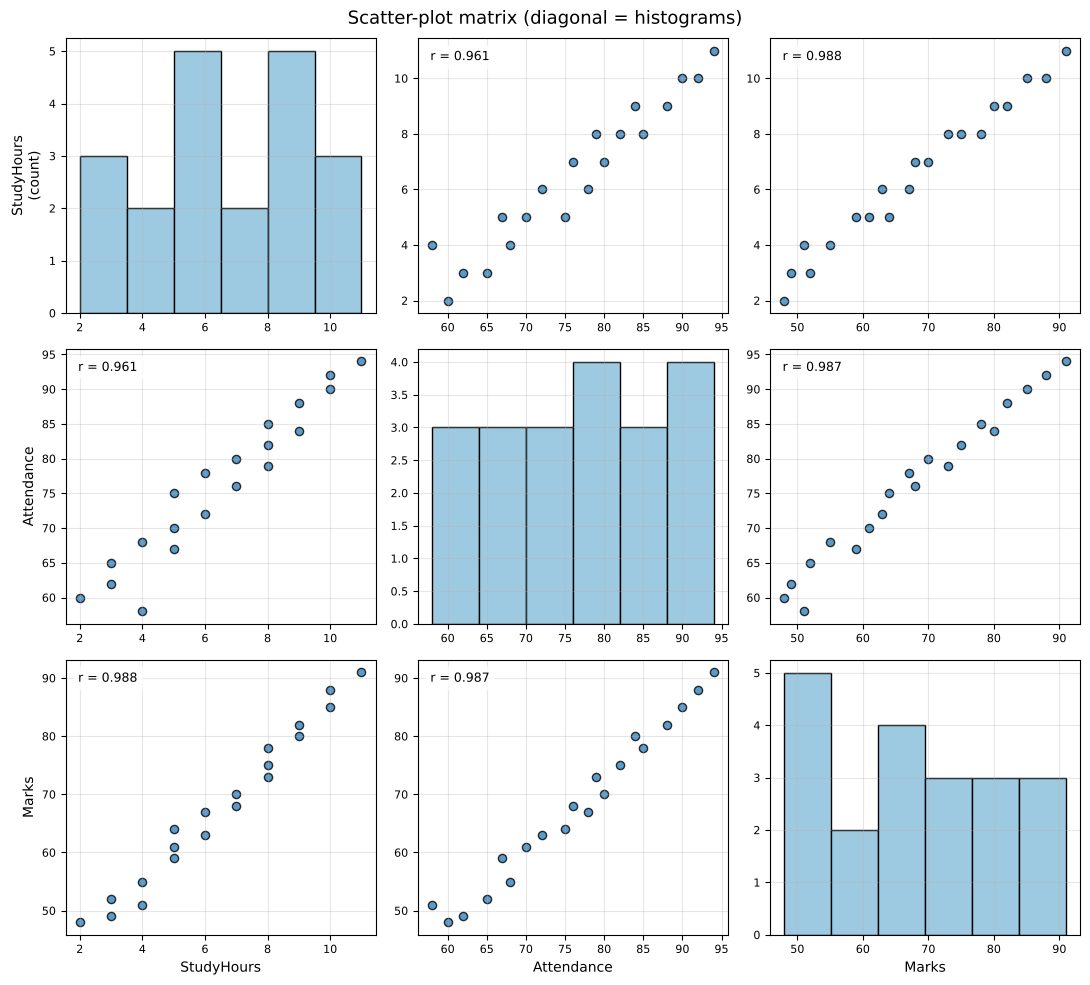

In [10]:
# Scatter-plot matrix: every pair of variables at once (diagonal = histograms).
# Built with plt.subplots so each panel keeps its own readable tick labels.
k = len(num_cols)
fig, axes = plt.subplots(k, k, figsize=(11, 10))
for i, yc in enumerate(num_cols):
    for j, xc in enumerate(num_cols):
        ax = axes[i, j]
        if i == j:
            ax.hist(df[xc], bins=6, color="#9ecae1", edgecolor="black")
            ax.set_ylabel("Count" if j == 0 else "")
        else:
            ax.scatter(df[xc], df[yc], s=35, color="#3182bd", edgecolor="black", alpha=0.8)
            ax.text(0.04, 0.92, f"r = {df[xc].corr(df[yc]):.3f}", transform=ax.transAxes, fontsize=9,
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
        if i == k - 1:
            ax.set_xlabel(xc)
        if j == 0 and i != j:
            ax.set_ylabel(yc)
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.3)
axes[0, 0].set_ylabel("StudyHours\n(count)")
fig.suptitle("Scatter-plot matrix (diagonal = histograms)", fontsize=13)
plt.tight_layout()
plt.show()

## (e) Pearson correlation matrix  *(15 marks)*

$$r = \frac{\sum (x-\bar{x})(y-\bar{y})}{\sqrt{\sum (x-\bar{x})^2 \sum (y-\bar{y})^2}}, \qquad -1 \le r \le 1$$

**Direction:** r > 0 positive (both rise together); r < 0 negative.
**Strength (common guideline for |r|):** 0–0.19 very weak, 0.20–0.39 weak, 0.40–0.59 moderate, 0.60–0.79 strong, **0.80–1.0 very strong**.

In [11]:
corr = df[num_cols].corr(method="pearson")
display(corr)

# Manual calculation for study hours vs marks (to show the formula)
x, y = df["StudyHours"], df["Marks"]
Sxy = np.sum((x - x.mean()) * (y - y.mean()))
Sxx = np.sum((x - x.mean()) ** 2)
Syy = np.sum((y - y.mean()) ** 2)
r_manual = Sxy / np.sqrt(Sxx * Syy)
print(f"Manual: Sxy = {Sxy:.4f}, Sxx = {Sxx:.4f}, Syy = {Syy:.4f}")
print(f"r = {Sxy:.4f} / sqrt({Sxx:.4f} x {Syy:.4f}) = {r_manual:.6f}")

,StudyHours,Attendance,Marks
StudyHours,1.0000,0.9606,0.9877
Attendance,0.9606,1.0000,0.9874
Marks,0.9877,0.9874,1.0000


Manual: Sxy = 652.5000, Sxx = 129.0000, Syy = 3382.9500
r = 652.5000 / sqrt(129.0000 x 3382.9500) = 0.987729


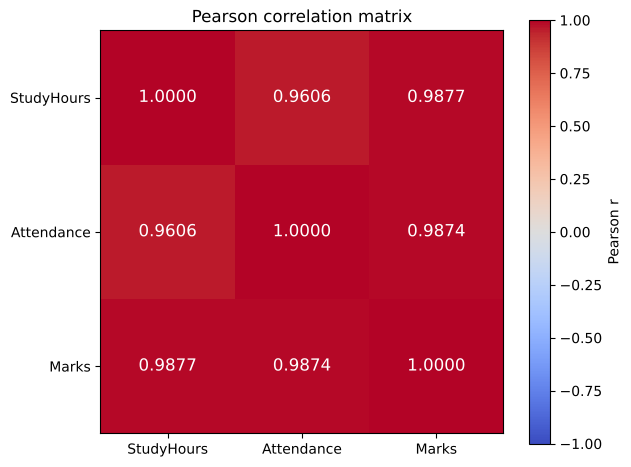

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(3))
ax.set_xticklabels(num_cols)
ax.set_yticks(range(3))
ax.set_yticklabels(num_cols)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.4f}", ha="center", va="center", fontsize=12,
                color="white" if abs(corr.iloc[i, j]) > 0.7 else "black")
fig.colorbar(im, label="Pearson r")
ax.set_title("Pearson correlation matrix")
plt.show()

In [13]:
def strength(r):
    a = abs(r)
    word = ("very weak" if a < 0.2 else "weak" if a < 0.4 else "moderate" if a < 0.6
            else "strong" if a < 0.8 else "very strong")
    return f"{word} {'positive' if r > 0 else 'negative'}"

for a, b in [("StudyHours", "Marks"), ("Attendance", "Marks"), ("StudyHours", "Attendance")]:
    r = corr.loc[a, b]
    print(f"{a:10s} vs {b:10s}: r = {r:.4f} -> {strength(r)};  R² = {r ** 2:.4f} "
          f"({r ** 2 * 100:.1f}% of the variation in one is linearly associated with the other)")

StudyHours vs Marks     : r = 0.9877 -> very strong positive;  R² = 0.9756 (97.6% of the variation in one is linearly associated with the other)
Attendance vs Marks     : r = 0.9874 -> very strong positive;  R² = 0.9750 (97.5% of the variation in one is linearly associated with the other)
StudyHours vs Attendance: r = 0.9606 -> very strong positive;  R² = 0.9228 (92.3% of the variation in one is linearly associated with the other)


## (f) Significance test of the study-hours correlation (α = 0.05)  *(15 marks)*

**Hypotheses** (ρ = population correlation):
* H₀: ρ = 0 (no linear relationship between study hours and marks)
* H₁: ρ ≠ 0 (a linear relationship exists), **two-tailed**

**Test statistic:** $t = \dfrac{r\sqrt{n-2}}{\sqrt{1-r^2}}$ with **df = n − 2 = 18**.

**Decision rule:** reject H₀ if |t| > t-critical (or equivalently if p-value < 0.05).

In [14]:
n = len(df)
r = df["StudyHours"].corr(df["Marks"])
dof = n - 2
t_stat = r * np.sqrt(dof) / np.sqrt(1 - r ** 2)
p_manual = 2 * stats.t.sf(abs(t_stat), dof)            # two-tailed p-value
t_crit = stats.t.ppf(1 - 0.05 / 2, dof)

print(f"n = {n}, r = {r:.6f}, df = {dof}")
print(f"t = {r:.6f} x sqrt({dof}) / sqrt(1 - {r:.6f}²) = {t_stat:.4f}")
print(f"Critical t (two-tailed, α = 0.05, df = {dof}) = ±{t_crit:.4f}")
print(f"p-value (manual) = {p_manual:.3e}")

# Same test with SciPy in one line
res = stats.pearsonr(df["StudyHours"], df["Marks"])
print(f"\nscipy.stats.pearsonr -> r = {res[0]:.6f}, p-value = {res[1]:.3e}")

n = 20, r = 0.987729, df = 18
t = 0.987729 x sqrt(18) / sqrt(1 - 0.987729²) = 26.8323
Critical t (two-tailed, α = 0.05, df = 18) = ±2.1009
p-value (manual) = 5.730e-16

scipy.stats.pearsonr -> r = 0.987729, p-value = 5.730e-16


In [15]:
# 95% confidence interval for ρ using Fisher's z-transformation
z = np.arctanh(r)
se = 1 / np.sqrt(n - 3)
lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
print(f"95% CI for ρ: ({lo:.4f}, {hi:.4f})  -> does not include 0")

decision = "REJECT H₀" if res[1] < 0.05 else "FAIL TO REJECT H₀"
print(f"\nDecision: |t| = {abs(t_stat):.2f} > {t_crit:.3f} and p = {res[1]:.2e} < 0.05 -> {decision}")

95% CI for ρ: (0.9686, 0.9952)  -> does not include 0

Decision: |t| = 26.83 > 2.101 and p = 5.73e-16 < 0.05 -> REJECT H₀


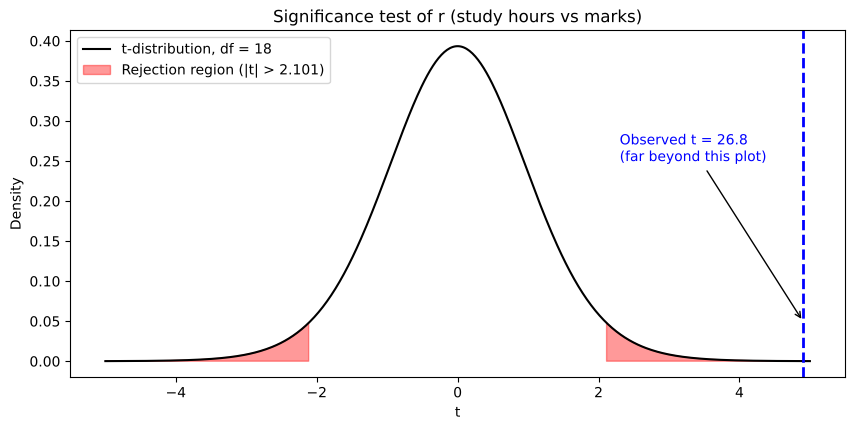

In [16]:
# Visualize the test: t-distribution with rejection regions
xs = np.linspace(-5, 5, 500)
plt.figure(figsize=(10, 4.5))
plt.plot(xs, stats.t.pdf(xs, dof), color="black", label=f"t-distribution, df = {dof}")
plt.fill_between(xs, stats.t.pdf(xs, dof), where=(np.abs(xs) >= t_crit), color="red", alpha=0.4,
                 label=f"Rejection region (|t| > {t_crit:.3f})")
plt.axvline(min(t_stat, 4.9), color="blue", lw=2, ls="--")
plt.annotate(f"Observed t = {t_stat:.1f}\n(far beyond this plot)", xy=(4.9, 0.05), xytext=(2.3, 0.25),
             arrowprops=dict(arrowstyle="->"), color="blue")
plt.xlabel("t")
plt.ylabel("Density")
plt.title("Significance test of r (study hours vs marks)")
plt.legend(loc="upper left")
plt.show()

**Result:** r = 0.9877, t = 26.83 with 18 df, and **p ≈ 5.7 × 10⁻¹⁶**, far below 0.05 (equivalently |t| = 26.83 > t-critical = 2.101). We **reject H₀**: there is a **statistically significant, very strong positive linear relationship** between study hours and examination marks. The 95% confidence interval for ρ, **(0.969, 0.995)**, is far from 0.

## (g) Comparing the relationships; outliers and assumptions  *(10 marks)*

In [17]:
# 1. Test all three correlations, and compare Pearson (linear) with Spearman (rank-based, robust to outliers)
rows = []
for a, b in [("StudyHours", "Marks"), ("Attendance", "Marks"), ("StudyHours", "Attendance")]:
    pr = stats.pearsonr(df[a], df[b])
    sr = stats.spearmanr(df[a], df[b])
    rows.append({"Pair": f"{a} – {b}", "Pearson r": pr[0], "Pearson p": pr[1],
                 "Spearman ρ": sr[0], "Spearman p": sr[1]})
table = pd.DataFrame(rows).set_index("Pair")
for c in ["Pearson p", "Spearman p"]:
    table[c] = table[c].map("{:.2e}".format)      # scientific notation: tiny p-values would show as 0.0000
display(table)

,Pearson r,Pearson p,Spearman ρ,Spearman p
Pair,,,,
StudyHours – Marks,0.9877,5.73e-16,0.9879,4.98e-16
Attendance – Marks,0.9874,7.21e-16,0.9895,1.45e-16
StudyHours – Attendance,0.9606,1.88e-11,0.9652,6.20e-12


In [18]:
# 2. Outlier check: z-scores of each variable, and standardized residuals of each simple regression
z_scores = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
print("Largest |z| per variable:", z_scores.abs().max().round(3).to_dict(), "-> none beyond 3")

for xcol in ["StudyHours", "Attendance"]:
    slope, intercept = np.polyfit(df[xcol], df["Marks"], 1)
    resid = df["Marks"] - (intercept + slope * df[xcol])
    std_resid = resid / resid.std(ddof=2)
    worst = std_resid.abs().idxmax()
    print(f"Marks ~ {xcol:10s}: largest standardized residual = {std_resid[worst]:+.2f} ({df.loc[worst, 'Student']}), "
          f"points with |std resid| > 2: {df.loc[std_resid.abs() > 2, 'Student'].tolist()}")

Largest |z| per variable: {'StudyHours': 1.727, 'Attendance': 1.687, 'Marks': 1.727} -> none beyond 3
Marks ~ StudyHours: largest standardized residual = -2.01 (S13), points with |std resid| > 2: ['S13']
Marks ~ Attendance: largest standardized residual = +2.43 (S13), points with |std resid| > 2: ['S13']


In [19]:
# 3. Influence check: recompute r leaving each student out in turn (leave-one-out)
for xcol in ["StudyHours", "Attendance"]:
    full = df[xcol].corr(df["Marks"])
    loo = pd.Series([df.drop(i)[xcol].corr(df.drop(i)["Marks"]) for i in df.index], index=df["Student"])
    print(f"Marks ~ {xcol:10s}: r (all) = {full:.4f} | leave-one-out range {loo.min():.4f} to {loo.max():.4f} | "
          f"without S13: r = {loo['S13']:.4f}")

Marks ~ StudyHours: r (all) = 0.9877 | leave-one-out range 0.9853 to 0.9899 | without S13: r = 0.9899
Marks ~ Attendance: r (all) = 0.9874 | leave-one-out range 0.9854 to 0.9919 | without S13: r = 0.9919


In [20]:
# 4. Hours and attendance are themselves strongly related -> partial correlation
#    (correlation of marks with one predictor after removing the linear effect of the other)
def residuals(y, x):
    b, a = np.polyfit(x, y, 1)
    return y - (a + b * x)

pc_hours = np.corrcoef(residuals(df["Marks"], df["Attendance"]), residuals(df["StudyHours"], df["Attendance"]))[0, 1]
pc_att = np.corrcoef(residuals(df["Marks"], df["StudyHours"]), residuals(df["Attendance"], df["StudyHours"]))[0, 1]
print(f"Partial r (Marks, StudyHours | Attendance) = {pc_hours:.4f}")
print(f"Partial r (Marks, Attendance | StudyHours) = {pc_att:.4f}")

Partial r (Marks, StudyHours | Attendance) = 0.8920
Partial r (Marks, Attendance | StudyHours) = 0.8891


**Comparison and discussion**

* **Both relationships are positive, very strong and significant, and almost equally strong:** study hours r = **0.9877** (R² = 97.6%) and attendance r = **0.9874** (R² = 97.5%). The difference (0.0003) is negligible. Neither predictor is clearly "better" from this data.
* **Spearman's rank correlation** gives nearly identical values (0.988 and 0.990). The relationships are **monotonic and consistent**, and their strength is not created by a few extreme values.
* **Outliers:** no variable has a z-score beyond ±3 (max |z| ≈ 1.7), so there are no univariate outliers. In the regressions, **S13** is the only point with a standardized residual beyond ±2. S13 studies 4 h but scores below the hours trend, and has the **lowest attendance (58%)** but scores *above* the attendance trend. It is a mild unusual point, not an error. Removing any single student changes r only in the third decimal place, so **no point is highly influential**. Pearson's r is sensitive to outliers in general, though. With n = 20, one extreme student could change it noticeably, so Spearman's ρ and the leave-one-out check are useful robustness checks.
* **Study hours and attendance are themselves highly correlated (r = 0.961).** Students who study more also attend more, so their separate contributions overlap (**multicollinearity**). The partial correlations (≈ 0.89 each) show that **each variable remains strongly related to marks even after controlling for the other**. Both seem to contribute, but the simple correlations above double-count their shared part.
* **Assumptions of Pearson's r and its t-test:**
  1. **Linearity:** the scatter plots show straight-line patterns ✅
  2. **Approximate (bivariate) normality:** Q–Q plots and Shapiro–Wilk ✅
  3. **No influential outliers:** checked above ✅ (S13 only mildly unusual)
  4. **Homoscedasticity:** the spread of points around the line looks roughly constant ✅
  5. **Independent observations:** assumed (each student measured once)
* **Caution:** correlations of about 0.99 are unusually high for real educational data. This looks like a small, idealized sample, so results may not generalize to a larger population.

## (h) Summary: correlation is not causation  *(10 marks)*

**Summary of findings**
1. The average student studies 6.5 hours, attends 76.25% of classes and scores 67.95 marks. All three variables are approximately normal and symmetric (histograms, Q–Q plots, Shapiro–Wilk p > 0.55), though slightly flatter than a bell curve.
2. **Study hours vs marks:** r = 0.988, a very strong positive relationship. It is **statistically significant** (t = 26.83, df = 18, p ≈ 5.7 × 10⁻¹⁶ < 0.05). Fitted trend: each extra study hour goes with about **5.06 more marks**.
3. **Attendance vs marks:** r = 0.987, also very strong and positive, practically as strong as study hours. Each extra 1% attendance goes with about 1.22 more marks.
4. Study hours and attendance are strongly inter-related (r = 0.961), so they partly measure the same underlying behaviour (engagement).

**Correlation ≠ causation**
* The analysis shows that students who study more **tend to** score higher. It does **not prove** that studying more **causes** the higher marks, because this is **observational** data, not a controlled experiment.
* **Confounding variables** may drive both: motivation, prior knowledge, aptitude, interest in the subject, health or family support. A motivated student is likely to study more, attend more *and* score more.
* **Reverse causation** is possible: students who do well may enjoy the subject and therefore study more.
* The two predictors overlap (multicollinearity), so we cannot cleanly separate the effect of attendance from the effect of study hours.
* **Establishing causation** would require a randomized controlled experiment (e.g. randomly assigning extra study sessions), or at least controlling for confounders in a multiple-regression model with a larger sample.

**Practical message:** encourage regular study and attendance, since they are strongly associated with better marks, while recognizing that the association alone does not prove that increasing hours will raise every student's marks by the same amount.